## BRT
1. Build presences/absences
2. Fit one full model + vessel-type-specific models
3. Extract relative importance of each driver, partial dependence plots
5. Tune hyperparameters


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio

gear_types = ["TRAWLERS", "DRIFTING_LONGLINES", "SQUID_JIGGER", "TUNA_PURSE_SEINES", None] # None = all gear types
period = "2017_2019"
gear_type = gear_types[4]
df_gaps = pd.read_csv(f"data/processed/gaps_{period}_filtered.csv")
df_fishing = pd.read_csv(f"data/raw/fishing_gridded_{period}.csv")
df_fishing



,lat,lon,gear_type,hours
0,-77.9,-176.7,set_longlines,0.075556
1,-77.8,-177.7,set_longlines,2.299722
2,-77.8,-177.6,set_longlines,0.864722
3,-77.8,-177.3,set_longlines,0.186111
4,-77.8,-176.7,set_longlines,0.686667
...,...,...,...,...
2334787,86.2,116.2,fishing,1.147500
2334788,86.2,116.3,fishing,1.148611
2334789,86.2,116.4,fishing,1.951667
2334790,86.2,116.5,fishing,1.600556


In [37]:
df_gaps

,start,end,id,type,position,regions,bounding_box,distances,vessel,encounter,fishing,gap,loitering,port_visit,duration_hours,start_distance_from_shore_km,vessel_id,gear_type
0,2017-01-21 09:20:04+00:00,2017-01-22 16:56:57+00:00,3bdc90a2712347db50d6b6ba99eecdc0,gap,"{'lat': 31.0785, 'lon': -170.837}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'NPFC'...","[-171.185185, 30.9829966667, -170.489515, 31.1...","{'start_distance_from_shore_km': 588.0, 'end_d...",{'id': '1147e3e02-2c03-56f8-0885-3643c0896772'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,31.614722,588.0,1147e3e02-2c03-56f8-0885-3643c0896772,POLE_AND_LINE
1,2017-01-09 02:58:25+00:00,2017-01-09 18:38:08+00:00,704bd86272cd43eba5bcb9d5343908cd,gap,"{'lat': 4.9303, 'lon': -18.4853}","{'mpa': [], 'eez': [], 'rfmo': ['ICCAT', 'ACAP...","[-18.800448333333332, 4.846435, -18.1701916667...","{'start_distance_from_shore_km': 698.0, 'end_d...",{'id': '13bf6bd39-9459-33e7-83ef-aacbe803d029'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,15.661944,698.0,13bf6bd39-9459-33e7-83ef-aacbe803d029,DRIFTING_LONGLINES
2,2017-01-28 00:11:49+00:00,2017-01-28 16:30:40+00:00,31a325ef26e6d7958b403e35c87da6cb,gap,"{'lat': 56.2954, 'lon': -167.3866}","{'mpa': [], 'eez': ['8463'], 'rfmo': ['ACAP', ...","[-167.5417933333, 56.2650366667, -167.231555, ...","{'start_distance_from_shore_km': 123.0, 'end_d...",{'id': '1d64fc20f-f64a-b17f-bbbc-6cb9475eb37e'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,16.314167,123.0,1d64fc20f-f64a-b17f-bbbc-6cb9475eb37e,POTS_AND_TRAPS
3,2017-01-11 21:13:05+00:00,2017-01-12 16:21:25+00:00,33bb0b2710a5a5651ae6ac59ff2cb95a,gap,"{'lat': 56.2089, 'lon': -167.3621}","{'mpa': [], 'eez': ['8463'], 'rfmo': ['ACAP', ...","[-167.4774566667, 56.11081, -167.2472516666666...","{'start_distance_from_shore_km': 127.0, 'end_d...",{'id': '1d64fc20f-f64a-b17f-bbbc-6cb9475eb37e'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,19.138889,127.0,1d64fc20f-f64a-b17f-bbbc-6cb9475eb37e,POTS_AND_TRAPS
4,2017-01-06 06:10:41+00:00,2017-01-07 03:30:15+00:00,2aae28fc35e79ca04e700b5a6d3adefe,gap,"{'lat': -45.6804, 'lon': -60.5852}","{'mpa': [], 'eez': [], 'rfmo': ['ICCAT', 'IWC'...","[-60.6501483333, -45.6912383333, -60.520263333...","{'start_distance_from_shore_km': 397.0, 'end_d...",{'id': '23c02e9d9-904d-2b0f-50bb-fbbb023c843c'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,21.326111,397.0,23c02e9d9-904d-2b0f-50bb-fbbb023c843c,TRAWLERS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85892,2019-12-24 11:21:49+00:00,2020-05-11 20:29:57+00:00,ef74d1fe32fb2cf2aa94bc2b0412a57c,gap,"{'lat': 23.7094, 'lon': 179.6589}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'WCPFC...","[179.40094, 10.9682833333, 179.97366166666666,...","{'start_distance_from_shore_km': 925.0, 'end_d...",{'id': '22bd2e044-4257-421d-7f68-85d8c86af475'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,3345.135556,925.0,22bd2e044-4257-421d-7f68-85d8c86af475,DRIFTING_LONGLINES
85893,2019-12-22 05:33:16+00:00,2020-05-16 13:25:53+00:00,fed315d1e0e7267576e53aac99e82bbb,gap,"{'lat': 17.2432, 'lon': 63.3783}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'IOTC'...","[62.6825066667, 15.8240833333, 64.0634733333, ...","{'start_distance_from_shore_km': 442.0, 'end_d...",{'id': '746191123-3ef3-c8ef-eea6-692632cef2f3'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,3511.876944,442.0,746191123-3ef3-c8ef-eea6-692632cef2f3,SQUID_JIGGER
85894,2019-12-28 11:15:19+00:00,2020-06-14 04:37:07+00:00,44733e8c26042113076fa6f84ba5f5c0,gap,"{'lat': 10.2268, 'lon': 83.772}","{'mpa': [], 'eez': [], 'rfmo': ['ACAP', 'IOTC'...","[65.19016, 2.4871633333, 101.5347666667, 16.96...","{'start_distance_from_shore_km': 690.0, 'end_d...",{'id': '0e15cf51d-d5fe-1c29-e286-d737550cb351'...,NaN,NaN,"{'intentional_disabling': True, 'distance_km':...",NaN,NaN,4049.363333,690.0,0e15cf51d-d5fe-1c29-e286-d73

## Build presences/ absences

In [38]:
import ast

def cell_center(lon, lat, res=0.25):
    lon_c = np.floor(lon / res) * res + res / 2
    lat_c = np.floor(lat / res) * res + res / 2
    return lon_c, lat_c

def build_presence_absence(gaps_df, fishing_df, res=0.25, seed=42, gear_type=None):
    if gear_type is not None:
        gaps_df = gaps_df[gaps_df['gear_type'].str.upper() == gear_type.upper()]
        fishing_df = fishing_df[fishing_df['gear_type'].str.upper() == gear_type.upper()]

    gaps_df = gaps_df.copy()
    gaps_df['position'] = gaps_df['position'].apply(lambda p: p if isinstance(p, dict) else ast.literal_eval(p))
    gaps_lat = gaps_df['position'].apply(lambda p: p['lat']).values
    gaps_lon = gaps_df['position'].apply(lambda p: p['lon']).values

    lon_c, lat_c = cell_center(gaps_lon, gaps_lat, res)
    presence_cells = set(zip(lon_c, lat_c))

    lon_f, lat_f = cell_center(fishing_df['lon'].values, fishing_df['lat'].values, res)
    fishing_cells = set(zip(lon_f, lat_f))

    candidate_absences = list(fishing_cells - presence_cells)
    print("Number of presences vs absences: ", len(presence_cells), len(candidate_absences))

    rng = np.random.default_rng(seed)
    n = min(len(presence_cells), len(candidate_absences))
    absence_idx = rng.choice(len(candidate_absences), size=n, replace=False)
    absence_cells = [candidate_absences[i] for i in absence_idx]

    presence_df = pd.DataFrame(list(presence_cells)[:n], columns=['lon', 'lat'])
    presence_df['presence'] = 1
    absence_df = pd.DataFrame(absence_cells, columns=['lon', 'lat'])
    absence_df['presence'] = 0

    pa_df = pd.concat([presence_df, absence_df], ignore_index=True)
    label = gear_type if gear_type else "full"
    print(f"[{label}] {presence_df.shape[0]} presences, {absence_df.shape[0]} absences")
    return pa_df

In [39]:
def debug_presence_absence(pa_df, gaps_df=None, fishing_df=None):
    n_presence = (pa_df['presence'] == 1).sum()
    n_absence = (pa_df['presence'] == 0).sum()
    print(f"Presences: {n_presence}, Absences: {n_absence}, ratio: {n_presence/n_absence:.2f}")

    dupes = pa_df.duplicated(subset=['lon', 'lat']).sum()
    print(f"Duplicate (lon,lat) rows: {dupes}")

    overlap = pd.merge(
        pa_df[pa_df['presence'] == 1][['lon', 'lat']],
        pa_df[pa_df['presence'] == 0][['lon', 'lat']],
        on=['lon', 'lat']
    )
    print(f"Cells present in both presence and absence sets: {len(overlap)}")  # should be 0

    print(pa_df.groupby('presence')[['lon', 'lat']].describe())

    fig, ax = plt.subplots(figsize=(15, 8))
    absences = pa_df[pa_df['presence'] == 0]
    presences = pa_df[pa_df['presence'] == 1]
    ax.scatter(absences['lon'], absences['lat'], s=2, c='red', alpha=0.4, label='Absence')
    ax.scatter(presences['lon'], presences['lat'], s=2, c='blue', alpha=0.6, label='Presence')
    ax.set_title(f"Presence/Absence check ({n_presence} vs {n_absence})")
    ax.legend()
    plt.show()

    return {"n_presence": n_presence, "n_absence": n_absence, "duplicates": dupes, "overlap": len(overlap)}

# pa_df = build_presence_absence(df_gaps, df_fishing)
# debug_presence_absence(pa_df)# 

## Extract drivers at presences/ absences grid cells

In [40]:
def sample_rasters(pa_df, raster_paths):
    """raster_paths: dict of {column_name: filepath}"""
    df = pa_df.copy()
    coords = list(zip(df['lon'], df['lat']))

    for col_name, path in raster_paths.items():
        with rasterio.open(path) as src:
            values = [v[0] for v in src.sample(coords)]
        df[col_name] = values

    return df

def get_raster_paths(period):
    return {
        "loitering_hours": f"data/processed/loitering_hours_{period}.tif",
        "dist2coast": "data/processed/dist2coast.tif",
        "dist_mpa": "data/processed/mpa_distance_combined.tif",
        "dist_piracy": "data/processed/asam_distance.tif",
        "chl": f"data/processed/chl_{period}.tif",
        "sst": f"data/processed/sst_{period}.tif",
        "sst_var": f"data/processed/sst_variability_{period}.tif",
        "eke": f"data/processed/eke_{period}.tif",
    }
raster_paths = get_raster_paths(period)
feature_cols = list(raster_paths.keys())

# model_df = sample_rasters(pa_df, raster_paths)
# # loitering_hours: NaN = no loitering recorded = 0 hours, not missing data
# model_df['loitering_hours'] = model_df['loitering_hours'].fillna(0)
# model_df.to_csv(f"data/processed/model_data_{period}.csv", index=False)

# # check for nan
# nan_summary = model_df[list(raster_paths.keys())].isna().sum()
# print(nan_summary)

# nan_rows = model_df[model_df[list(raster_paths.keys())].isna().any(axis=1)]
# print(f"{len(nan_rows)} / {len(model_df)} rows affected")
# print(nan_rows.groupby('presence').size())  # check class balance impact

def rebalance_1to1(df, seed=42):
    n = df['presence'].value_counts().min()
    return (
        df.groupby('presence', group_keys=False)
        .apply(lambda g: g.sample(n, random_state=seed))
        .reset_index(drop=True)
    )

# model_df = rebalance_1to1(model_df)
# print(model_df.groupby('presence').size())

In [41]:

from sklearn.metrics import log_loss
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt
import numpy as np

def explained_deviance(y_true, y_pred_proba):
    model_dev = 2 * log_loss(y_true, y_pred_proba, normalize=False)
    null_pred = np.full_like(y_true, y_true.mean(), dtype=float)
    null_dev = 2 * log_loss(y_true, null_pred, normalize=False)
    return (null_dev - model_dev) / null_dev * 100

def fit_brt(model_df, feature_cols, n_iter=50, seed=42, **xgb_params):
    X = model_df[feature_cols]
    y = model_df["presence"]

    params = dict(
        n_estimators=1000,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.6,
        eval_metric="logloss",
        random_state=seed,
    )
    params.update(xgb_params)

    aucs, tss_scores = [], []
    for i in range(n_iter):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=seed + i, stratify=y
        )
        clf = xgb.XGBClassifier(**{**params, "random_state": seed + i})
        clf.fit(X_train, y_train)
        preds = clf.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, preds))

        pred_labels = (preds >= 0.5).astype(int)
        tp = ((pred_labels == 1) & (y_test == 1)).sum()
        tn = ((pred_labels == 0) & (y_test == 0)).sum()
        fp = ((pred_labels == 1) & (y_test == 0)).sum()
        fn = ((pred_labels == 0) & (y_test == 1)).sum()
        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)
        tss_scores.append(sensitivity + specificity - 1)

    # final model trained on all data
    final_model = xgb.XGBClassifier(**params)
    final_model.fit(X, y)
    dev = explained_deviance(y, final_model.predict_proba(X)[:, 1])

    metrics = {
        "explained_deviance": dev,
        "auc_mean": np.mean(aucs), "auc_std": np.std(aucs),
        "tss_mean": np.mean(tss_scores), "tss_std": np.std(tss_scores),
        "n_presence": int((y == 1).sum()), "n_absence": int((y == 0).sum()),
    }
    print(f"Explained deviance: {dev:.2f}%  AUC: {metrics['auc_mean']:.3f} ± {metrics['auc_std']:.3f}  "
          f"TSS: {metrics['tss_mean']:.3f} ± {metrics['tss_std']:.3f}")

    return final_model, metrics

def plot_importance(model, feature_cols, title="Feature importance"):
    importances = model.feature_importances_
    order = np.argsort(importances)[::-1]
    plt.barh([feature_cols[i] for i in order], importances[order])
    plt.title(title)
    plt.gca().invert_yaxis()
    plt.show()


# Run model per geartype and save results

Number of presences vs absences:  34749 284586
[full] 34749 presences, 34749 absences


/tmp/ipykernel_27978/1578537376.py:44: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n, random_state=seed))


Explained deviance: 19.80%  AUC: 0.767 ± 0.003  TSS: 0.391 ± 0.006


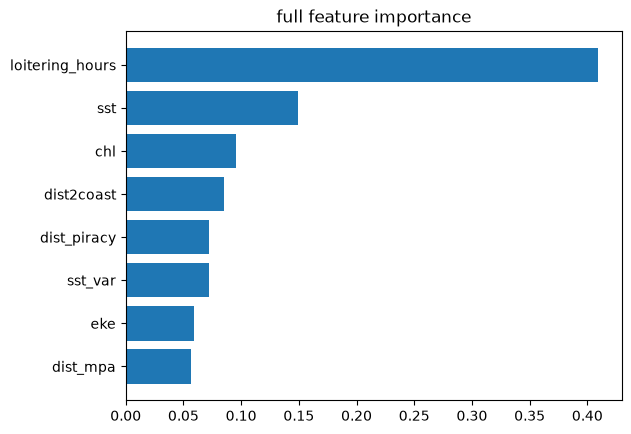

Saved metrics + importance for 'full' -> model_results


In [42]:
import os
import json

def run_model(gaps_df, fishing_df, feature_cols, raster_paths, gear_type=None, outdir="model_results"):
    os.makedirs(outdir, exist_ok=True)
    label = gear_type if gear_type else "full"

    pa_df = build_presence_absence(gaps_df, fishing_df, gear_type=gear_type)
    model_df = sample_rasters(pa_df, raster_paths)
    # loitering_hours: NaN = no loitering recorded = 0 hours, not missing data
    model_df = sample_rasters(pa_df, raster_paths)
    model_df['loitering_hours'] = model_df['loitering_hours'].fillna(0)
    model_df = model_df.dropna(subset=[c for c in feature_cols if c != 'loitering_hours'])
    model_df = rebalance_1to1(model_df)
    
    model, metrics = fit_brt(model_df, feature_cols)

    with open(f"{outdir}/metrics_{label}.json", "w") as f:
        json.dump(metrics, f, indent=2)

    importances = model.feature_importances_
    importance_dict = dict(zip(feature_cols, [float(v) for v in importances]))
    importance_dict = dict(sorted(importance_dict.items(), key=lambda x: x[1], reverse=True))

    with open(f"{outdir}/importance_{label}.json", "w") as f:
        json.dump(importance_dict, f, indent=2)

    plot_importance(model, feature_cols, title=f"{label} feature importance")
    plt.savefig(f"{outdir}/importance_{label}.png", dpi=150, bbox_inches="tight")
    plt.close()

    print(f"Saved metrics + importance for '{label}' -> {outdir}")
    return model_df, model, metrics

model_df, model, metrics = run_model(df_gaps, df_fishing, feature_cols, raster_paths, gear_type=gear_type)

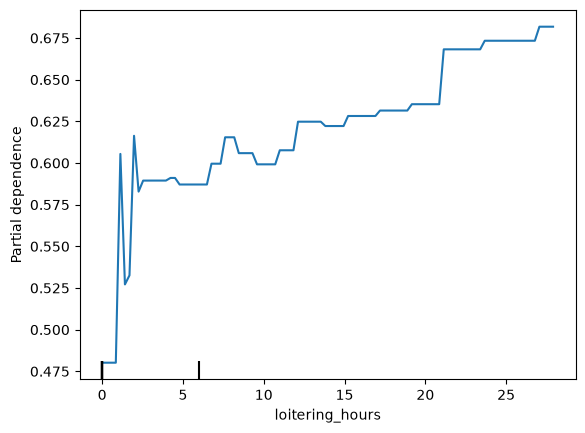

In [44]:
from sklearn.inspection import PartialDependenceDisplay
PartialDependenceDisplay.from_estimator(model, model_df[feature_cols], ["loitering_hours"])